In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, f1_score, classification_report, confusion_matrix)
from statsmodels.tsa.holtwinters import ExponentialSmoothing

sns.set_theme(style="whitegrid")
os.makedirs("models", exist_ok=True)
os.makedirs("data", exist_ok=True)
RANDOM_STATE = 42


In [3]:
df = pd.read_csv("uber_trips_dataset.csv")
print(df.shape)
df.head()

(50000, 15)


,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,distance_km,fare_amount,status,payment_method,pickup_time,drop_time,output
0,1,8270,10683,San Francisco,37.170931,-77.586479,37.173652,-77.619934,2.97,10.71,Completed,Wallet,01-01-2023 00:00,08:54.6,High Demand
1,2,1860,44743,Boston,38.898127,-108.582977,38.937464,-108.558727,8.43,22.41,Completed,UPI,01-01-2023 00:01,26:17.4,High Demand
2,3,6390,75839,San Francisco,38.814571,-89.942603,38.821702,-89.896435,5.46,12.91,Completed,Cash,01-01-2023 00:02,18:22.8,High Demand
3,4,6191,22189,New York,37.295906,-75.328844,37.301375,-75.317488,6.61,15.70,Completed,Wallet,01-01-2023 00:03,22:49.8,Low Demand
4,5,6734,61104,Seattle,38.972395,-121.482913,38.992088,-121.467904,10.50,19.15,Completed,Wallet,01-01-2023 00:04,35:30.0,Low Demand


In [4]:
df.info()
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate trip_ids:", df.trip_id.duplicated().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   trip_id         50000 non-null  int64  
 1   driver_id       50000 non-null  int64  
 2   rider_id        50000 non-null  int64  
 3   city            50000 non-null  str    
 4   pickup_lat      50000 non-null  float64
 5   pickup_lng      50000 non-null  float64
 6   drop_lat        50000 non-null  float64
 7   drop_lng        50000 non-null  float64
 8   distance_km     50000 non-null  float64
 9   fare_amount     50000 non-null  float64
 10  status          50000 non-null  str    
 11  payment_method  50000 non-null  str    
 12  pickup_time     50000 non-null  str    
 13  drop_time       50000 non-null  str    
 14  output          50000 non-null  str    
dtypes: float64(6), int64(3), str(6)
memory usage: 8.4 MB

Missing values:
 trip_id           0
driver_id         0
rider_id          0
c

,count,mean,std,min,25%,50%,75%,max
trip_id,50000.0,25000.500000,14433.901067,1.000000,12500.750000,25000.500000,37500.250000,50000.000000
driver_id,50000.0,5493.954540,2601.410798,1000.000000,3232.750000,5497.000000,7746.000000,9998.000000
rider_id,50000.0,55040.994580,25915.467105,10001.000000,32539.000000,55164.000000,77293.500000,99998.000000
pickup_lat,50000.0,38.998664,1.155241,37.000009,37.994428,38.992589,39.999602,40.999937
pickup_lng,50000.0,-97.485552,14.173744,-121.999465,-109.818282,-97.463042,-85.190954,-73.001961
drop_lat,50000.0,38.998768,1.155696,36.953365,37.998237,38.994190,39.998849,41.047536
drop_lng,50000.0,-97.485677,14.173735,-122.047123,-109.817260,-97.464646,-85.199652,-72.963476
distance_km,50000.0,7.008070,2.946744,0.000000,4.980000,6.980000,9.000000,19.410000
fare_amount,50000.0,15.976205,6.274406,1.080000,11.510000,15.430000,19.910000,50.670000


In [5]:
# Categorical columns
for c in ["city", "status", "payment_method", "output"]:
    print(c, df[c].value_counts().to_dict(), "\n")

city {'Boston': 8454, 'San Francisco': 8401, 'Chicago': 8345, 'Los Angeles': 8315, 'New York': 8247, 'Seattle': 8238} 

status {'Completed': 42540, 'Cancelled': 4984, 'No-Show': 2476} 

payment_method {'UPI': 12549, 'Card': 12533, 'Wallet': 12505, 'Cash': 12413} 

output {'Low Demand': 19044, 'High Demand': 15839, 'Medium Demand': 15117} 



In [6]:
df = df.rename(columns={"output": "demand_level"})

# --- datetime features
df["pickup_time"] = pd.to_datetime(df["pickup_time"], format="%d-%m-%Y %H:%M")
df["date"] = df["pickup_time"].dt.date
df["hour"] = df["pickup_time"].dt.hour
df["day_of_week"] = df["pickup_time"].dt.dayofweek          # 0 = Monday
df["day_name"] = df["pickup_time"].dt.day_name()
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)
df["time_of_day"] = pd.cut(df["hour"], bins=[-1, 5, 11, 16, 20, 23],
                           labels=["Night", "Morning", "Afternoon", "Evening", "Late Night"])

# --- duration: 'MM:SS.s' -> minutes
def to_minutes(s):
    m, sec = s.split(":")
    return int(m) + float(sec) / 60
df["duration_min"] = df["drop_time"].apply(to_minutes)

# --- derived trip metrics
df["fare_per_km"] = np.where(df["distance_km"] > 0, df["fare_amount"] / df["distance_km"], np.nan)
df["speed_kmph"] = np.where(df["duration_min"] > 0, df["distance_km"] / (df["duration_min"] / 60), np.nan)
df["is_completed"] = (df["status"] == "Completed").astype(int)

print("Date range:", df.pickup_time.min(), "->", df.pickup_time.max())
df[["pickup_time", "hour", "day_name", "duration_min", "fare_per_km", "speed_kmph"]].head()

# ----------------------- CELL 6 (copy from here) -----------------------
# Outlier check (IQR) on key numeric columns
for c in ["distance_km", "fare_amount", "duration_min"]:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(f"{c}: {n} IQR outliers ({n/len(df):.2%})")

Date range: 2023-01-01 00:00:00 -> 2023-02-04 17:19:00
distance_km: 208 IQR outliers (0.42%)
fare_amount: 495 IQR outliers (0.99%)
duration_min: 0 IQR outliers (0.00%)


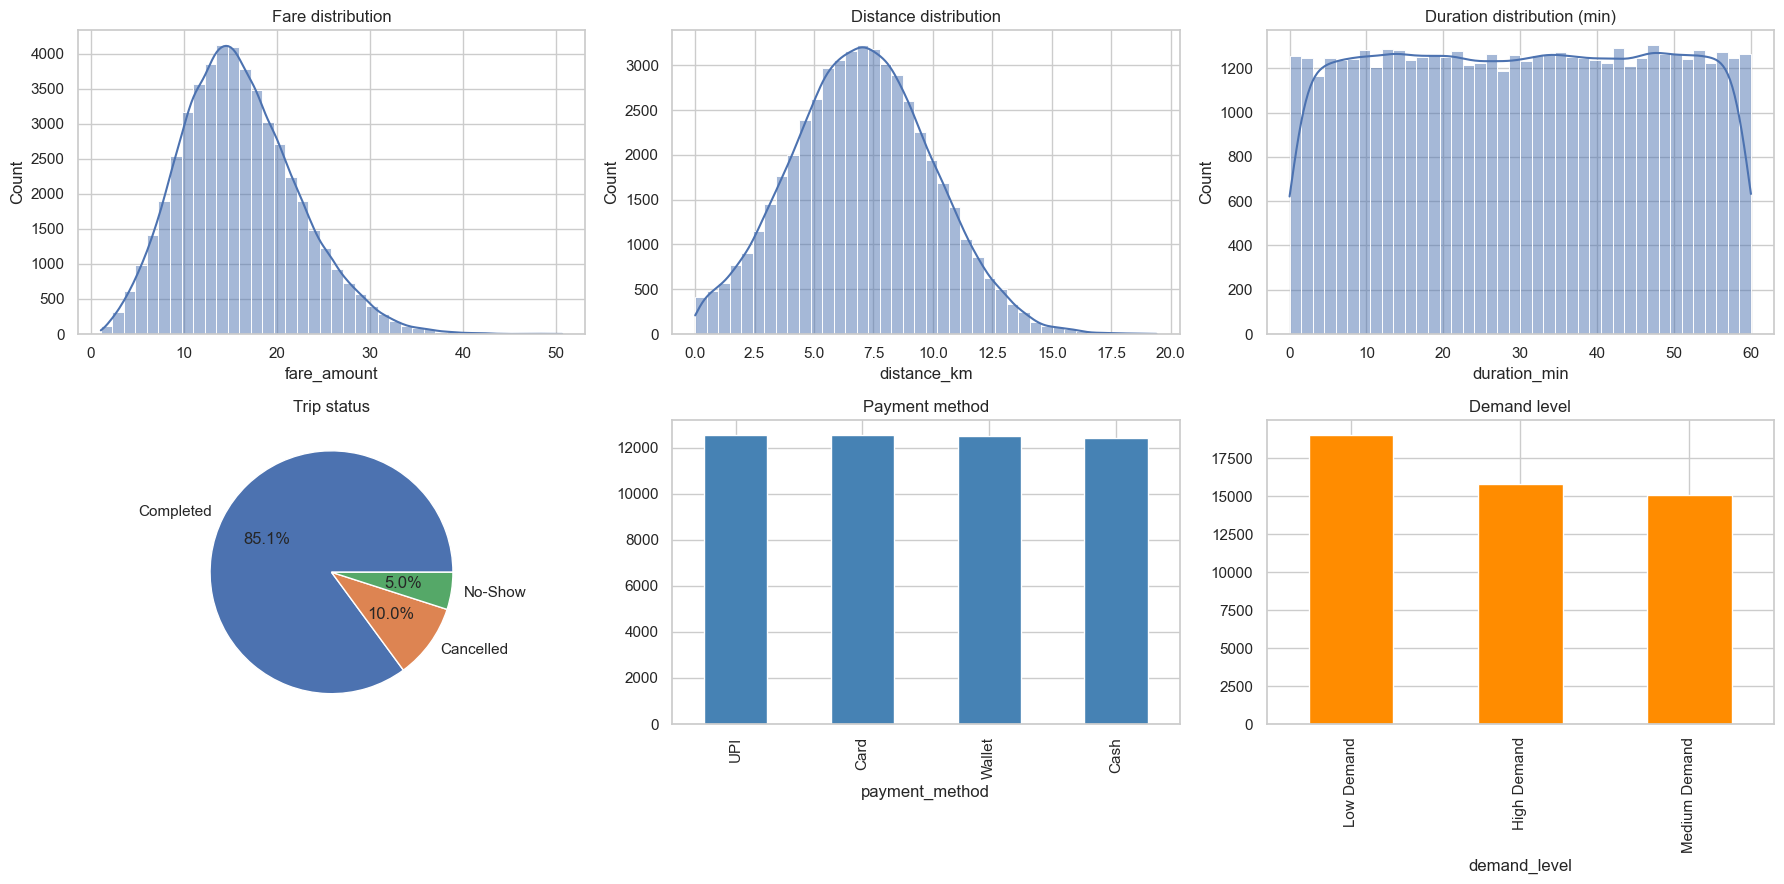

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
sns.histplot(df.fare_amount, bins=40, kde=True, ax=axes[0,0]); axes[0,0].set_title("Fare distribution")
sns.histplot(df.distance_km, bins=40, kde=True, ax=axes[0,1]); axes[0,1].set_title("Distance distribution")
sns.histplot(df.duration_min, bins=40, kde=True, ax=axes[0,2]); axes[0,2].set_title("Duration distribution (min)")
df.status.value_counts().plot.pie(autopct="%1.1f%%", ax=axes[1,0], ylabel=""); axes[1,0].set_title("Trip status")
df.payment_method.value_counts().plot.bar(ax=axes[1,1], color="steelblue"); axes[1,1].set_title("Payment method")
df.demand_level.value_counts().plot.bar(ax=axes[1,2], color="darkorange"); axes[1,2].set_title("Demand level")
plt.tight_layout(); plt.show()


In [8]:
city_summary = df.groupby("city").agg(
    trips=("trip_id", "count"),
    avg_fare=("fare_amount", "mean"),
    avg_distance=("distance_km", "mean"),
    completion_rate=("is_completed", "mean"),
    revenue=("fare_amount", lambda s: s[df.loc[s.index, "is_completed"] == 1].sum()),
).round(2).sort_values("trips", ascending=False)
city_summary


,trips,avg_fare,avg_distance,completion_rate,revenue
city,,,,,
Boston,8454,16.05,7.02,0.85,115028.20
San Francisco,8401,16.02,7.03,0.85,114660.65
Chicago,8345,15.90,6.96,0.85,112791.09
Los Angeles,8315,15.77,6.95,0.85,110686.54
New York,8247,16.05,7.01,0.85,113175.20
Seattle,8238,16.06,7.07,0.85,113343.20


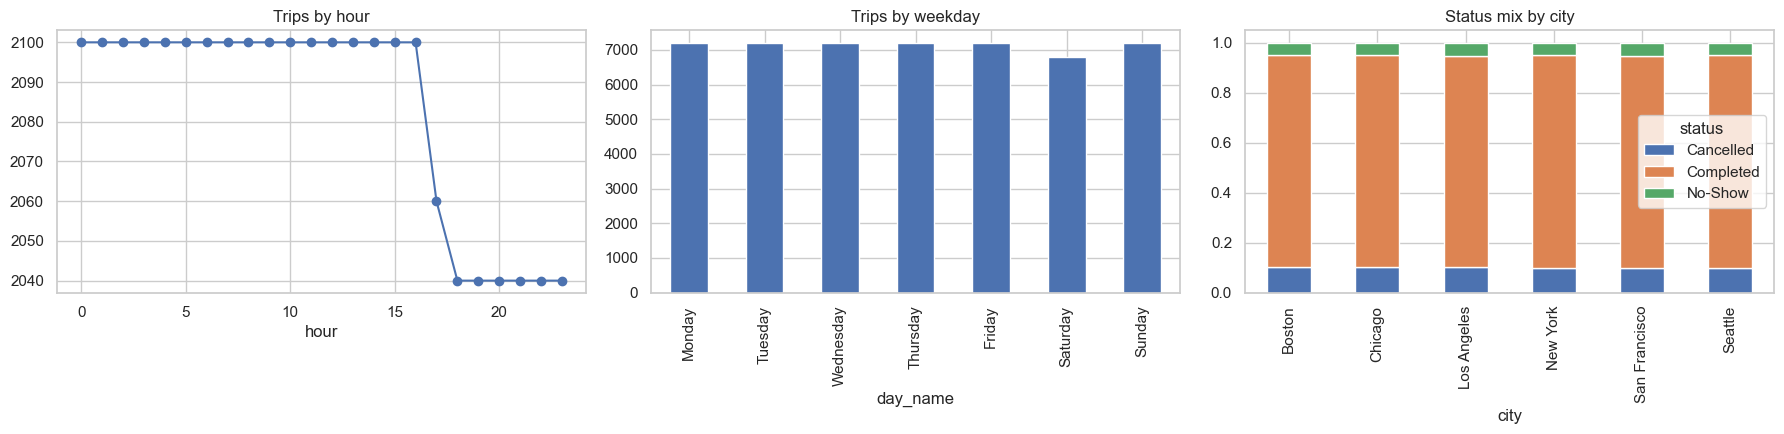

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
df.groupby("hour").size().plot(ax=axes[0], marker="o"); axes[0].set_title("Trips by hour")
df.groupby("day_name").size().reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]).plot.bar(ax=axes[1]); axes[1].set_title("Trips by weekday")
pd.crosstab(df.city, df.status, normalize="index").plot.bar(stacked=True, ax=axes[2]); axes[2].set_title("Status mix by city")
plt.tight_layout(); plt.show()

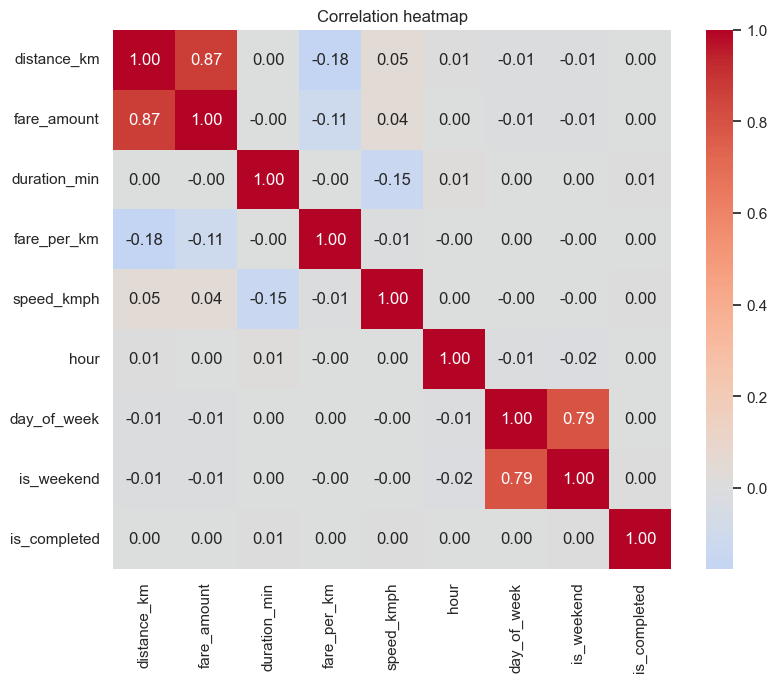

Correlation of each feature with fare_amount:


distance_km     0.870630
speed_kmph      0.041394
hour            0.002007
is_completed    0.000511
duration_min   -0.001229
is_weekend     -0.006737
day_of_week    -0.009459
fare_per_km    -0.107617
Name: fare_amount, dtype: float64

In [10]:
num_cols = ["distance_km", "fare_amount", "duration_min", "fare_per_km", "speed_kmph",
            "hour", "day_of_week", "is_weekend", "is_completed"]
corr = df[num_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap"); plt.show()

print("Correlation of each feature with fare_amount:")
corr["fare_amount"].drop("fare_amount").sort_values(ascending=False)

In [11]:
# Categorical vs numeric: does fare differ across groups? (ANOVA / Kruskal)
from scipy import stats
for cat in ["city", "payment_method", "status", "demand_level"]:
    groups = [g.fare_amount.values for _, g in df.groupby(cat)]
    h, p = stats.kruskal(*groups)
    print(f"fare_amount by {cat:15s} Kruskal-Wallis p = {p:.4f}  ->", "significant" if p < 0.05 else "no significant difference")

fare_amount by city            Kruskal-Wallis p = 0.0718  -> no significant difference
fare_amount by payment_method  Kruskal-Wallis p = 0.8685  -> no significant difference
fare_amount by status          Kruskal-Wallis p = 0.9604  -> no significant difference
fare_amount by demand_level    Kruskal-Wallis p = 0.6774  -> no significant difference


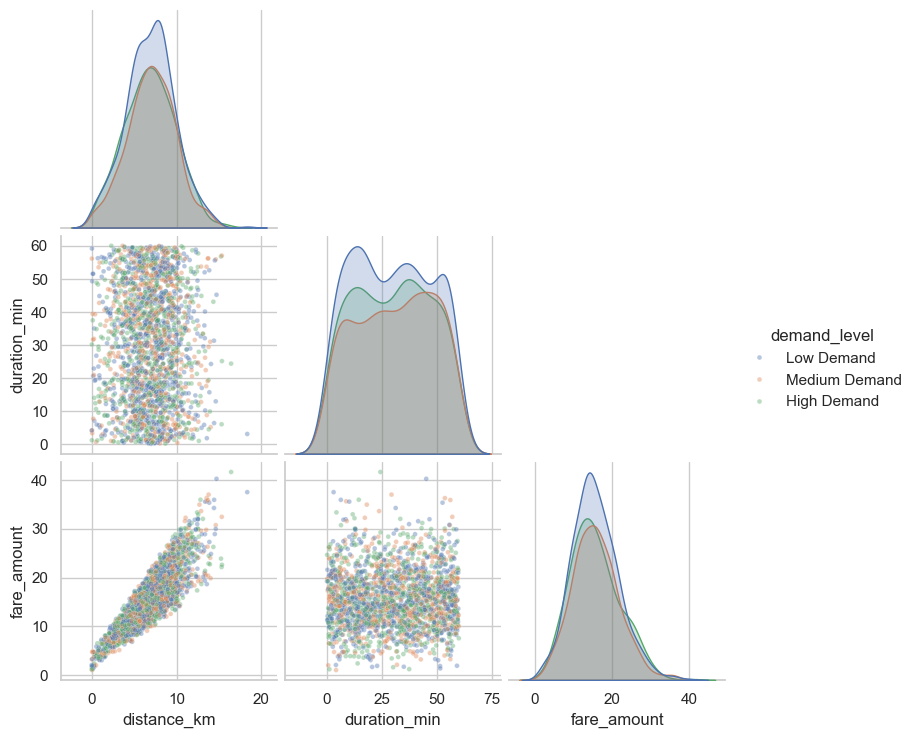

In [12]:
sns.pairplot(df.sample(2000, random_state=1)[["distance_km", "duration_min", "fare_amount", "demand_level"]],
             hue="demand_level", corner=True, plot_kws={"alpha": .4, "s": 12})
plt.show()

In [13]:
# ## Step 5: Predictive model 1: **Regression** (predict `fare_amount`)
# Features that are known *before/at* booking: distance, hour, weekday, city, payment method.
# (`duration_min` is only known after the trip, so we compare with and without it.)

# ----------------------- CELL 13 (copy from here) -----------------------
target = "fare_amount"
num_feats = ["distance_km", "hour", "day_of_week", "is_weekend"]
cat_feats = ["city", "payment_method"]

X = df[num_feats + cat_feats]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

pre = ColumnTransformer([
    ("num", StandardScaler(), num_feats),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_feats),
])

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}
rows, fitted = [], {}
for name, m in models.items():
    pipe = Pipeline([("pre", pre), ("model", m)]).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({"Model": name,
                 "MAE": mean_absolute_error(y_test, pred),
                 "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                 "R2": r2_score(y_test, pred)})
    fitted[name] = pipe
reg_results = pd.DataFrame(rows).round(3).sort_values("RMSE")
reg_results


,Model,MAE,RMSE,R2
0,Linear Regression,2.487,3.102,0.761
2,Gradient Boosting,2.490,3.105,0.761
1,Random Forest,2.554,3.203,0.745


Best regression model: Linear Regression


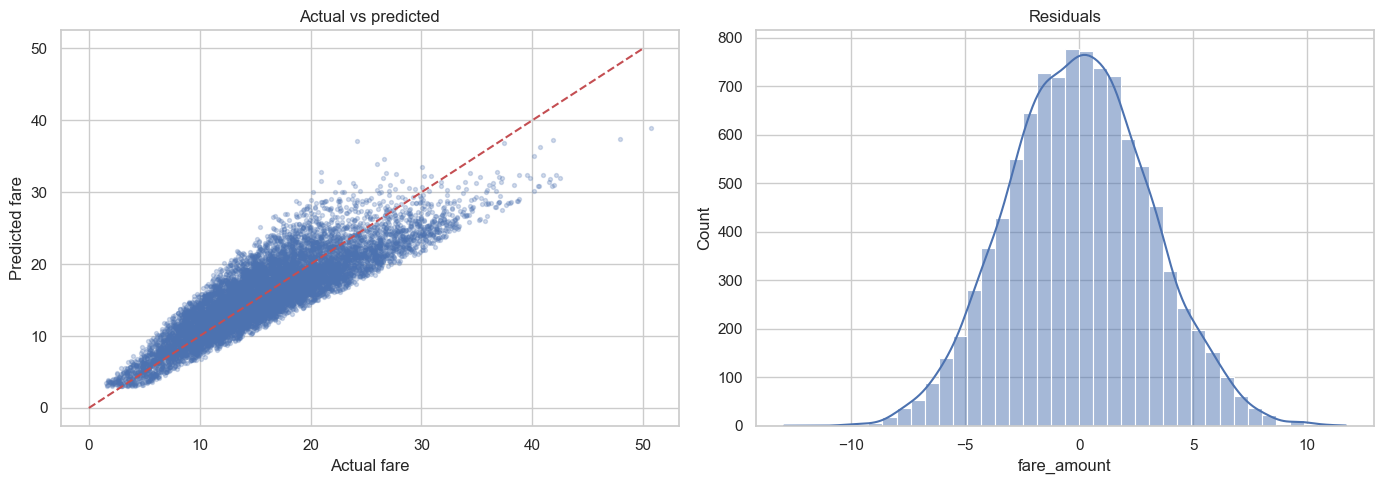

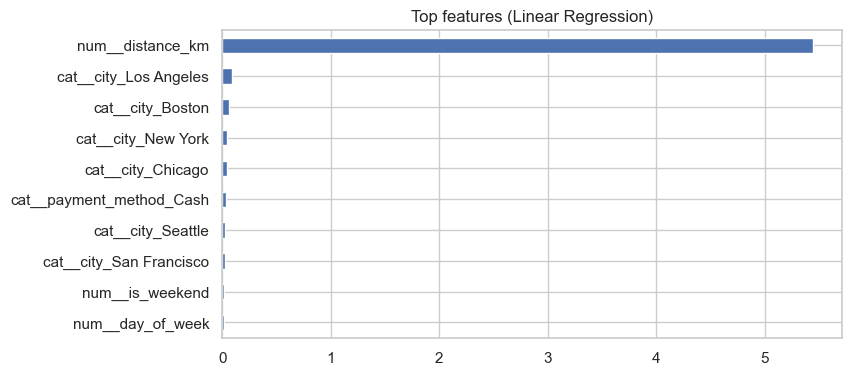

Saved models/fare_model.joblib


In [16]:
# ---- REPLACEMENT for old cells 14, 15, 16 (run after the regression-models cell) ----
best_reg_name = reg_results.sort_values("RMSE").iloc[0]["Model"]
best_reg = fitted[best_reg_name]
pred = best_reg.predict(X_test)
print("Best regression model:", best_reg_name)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, pred, alpha=.25, s=8); axes[0].plot([0, 50], [0, 50], "r--")
axes[0].set_xlabel("Actual fare"); axes[0].set_ylabel("Predicted fare"); axes[0].set_title("Actual vs predicted")
sns.histplot(y_test - pred, bins=40, kde=True, ax=axes[1]); axes[1].set_title("Residuals")
plt.tight_layout(); plt.show()

# feature importance / coefficients (works with any sklearn version)
est = best_reg.named_steps["model"]
pre_fit = best_reg.named_steps["pre"]
try:
    feature_names = pre_fit.get_feature_names_out()
except AttributeError:
    feature_names = num_feats + list(pre_fit.named_transformers_["cat"].get_feature_names(cat_feats))
imp = est.feature_importances_ if hasattr(est, "feature_importances_") else np.abs(est.coef_)
pd.Series(imp, index=feature_names).sort_values().tail(10).plot.barh(figsize=(8, 4), title=f"Top features ({best_reg_name})")
plt.show()

# save the model
os.makedirs("models", exist_ok=True)
joblib.dump(best_reg, "models/fare_model.joblib")
print("Saved models/fare_model.joblib")

(834, 3)


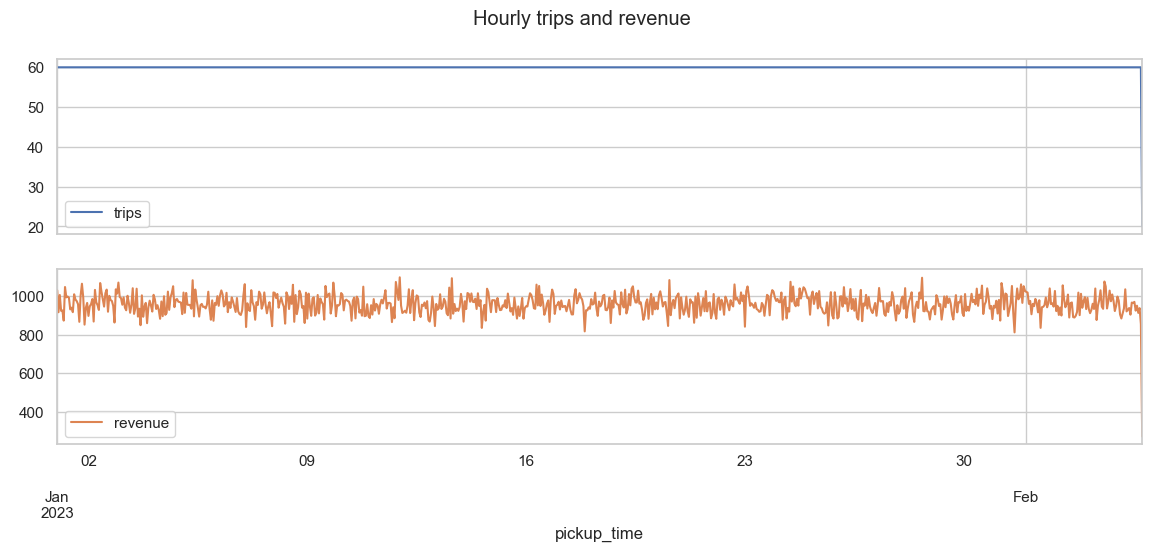

In [17]:
# ## Step 6: Predictive model 2: **Time-series forecasting**
# We aggregate to **hourly** totals (trips and revenue) and forecast the next 48 hours with Holt-Winters (24-hour seasonality). We compare against a *seasonal-naive* baseline so we know whether the model adds any value.

# ----------------------- CELL 17 (copy from here) -----------------------
hourly = (df.set_index("pickup_time")
            .resample("h")
            .agg(trips=("trip_id", "count"), revenue=("fare_amount", "sum"), avg_fare=("fare_amount", "mean")))
# last day is partial: drop incomplete trailing hours
hourly = hourly[hourly.trips > 0]
print(hourly.shape)
hourly[["trips", "revenue"]].plot(subplots=True, figsize=(14, 5), title="Hourly trips and revenue")
plt.show()


,MAE,RMSE,MAPE %
Holt-Winters,49.96,108.50,8.92
Seasonal naive,60.30,111.33,9.70


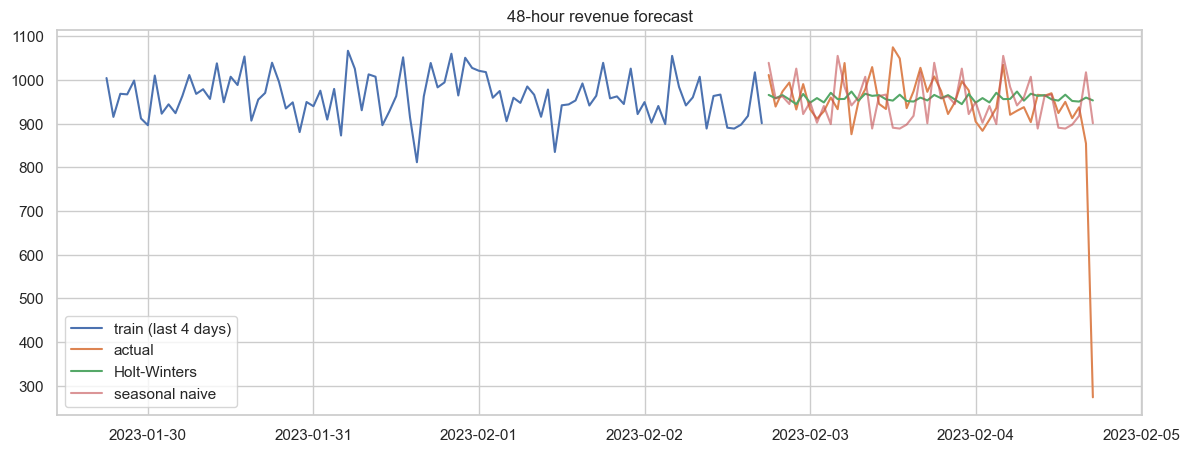

In [18]:
series = hourly["revenue"]
H = 48                                   # forecast horizon (hours)
train_ts, test_ts = series.iloc[:-H], series.iloc[-H:]

hw = ExponentialSmoothing(train_ts, trend=None, seasonal="add", seasonal_periods=24).fit()
hw_fc = hw.forecast(H)

naive_fc = train_ts.iloc[-24:].values.tolist() * (H // 24)      # seasonal naive
naive_fc = pd.Series(naive_fc, index=test_ts.index)

def metrics(a, f):
    return {"MAE": mean_absolute_error(a, f),
            "RMSE": np.sqrt(mean_squared_error(a, f)),
            "MAPE %": (np.abs((a - f) / a).mean()) * 100}

ts_results = pd.DataFrame({"Holt-Winters": metrics(test_ts, hw_fc),
                           "Seasonal naive": metrics(test_ts, naive_fc)}).T.round(2)
display(ts_results)

plt.figure(figsize=(14, 5))
plt.plot(train_ts.iloc[-96:], label="train (last 4 days)")
plt.plot(test_ts, label="actual"); plt.plot(hw_fc, label="Holt-Winters"); plt.plot(naive_fc, label="seasonal naive", alpha=.6)
plt.legend(); plt.title("48-hour revenue forecast"); plt.show()


In [19]:
# Refit on all data and forecast the *future* 48 hours for the dashboard
final_hw = ExponentialSmoothing(series, trend=None, seasonal="add", seasonal_periods=24).fit()
future_fc = final_hw.forecast(48).rename("forecast_revenue")
future_fc.to_frame().to_csv("data/forecast.csv")
hourly.to_csv("data/hourly_series.csv")
future_fc.head()


2023-02-04 18:00:00    968.387379
2023-02-04 19:00:00    958.093206
2023-02-04 20:00:00    964.327175
2023-02-04 21:00:00    956.303858
2023-02-04 22:00:00    945.879516
Freq: h, Name: forecast_revenue, dtype: float64

['city']                                 groups=    6  purity=0.39
['hour']                                 groups=   24  purity=0.418
['city', 'hour']                         groups=  144  purity=0.532
['city', 'payment_method']               groups=   24  purity=0.391
['city', 'day_of_week', 'hour']          groups= 1008  purity=1.0
=== Demand level ===  (majority-class baseline accuracy = 0.381)


,Model,Accuracy,Macro F1
0,Logistic Regression,0.397,0.388
1,Random Forest,1.000,1.000


Best: Random Forest
               precision    recall  f1-score   support

  High Demand       1.00      1.00      1.00      3168
   Low Demand       1.00      1.00      1.00      3809
Medium Demand       1.00      1.00      1.00      3023

     accuracy                           1.00     10000
    macro avg       1.00      1.00      1.00     10000
 weighted avg       1.00      1.00      1.00     10000



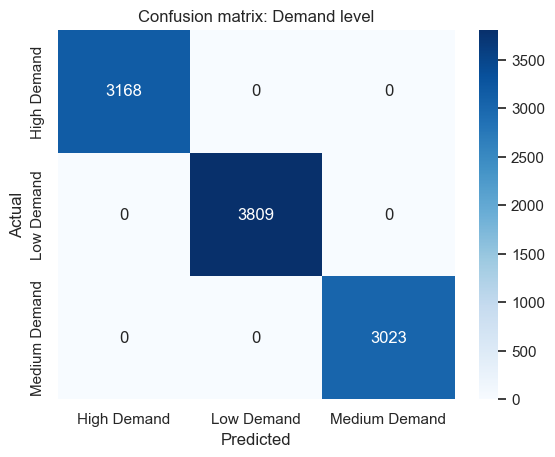

=== Trip completion ===  (majority-class baseline accuracy = 0.851)


,Model,Accuracy,Macro F1
0,Logistic Regression,0.504,0.429
1,Random Forest,0.678,0.501


Best: Random Forest
               precision    recall  f1-score   support

    Completed       0.85      0.75      0.80      8508
Not completed       0.16      0.28      0.20      1492

     accuracy                           0.68     10000
    macro avg       0.51      0.51      0.50     10000
 weighted avg       0.75      0.68      0.71     10000



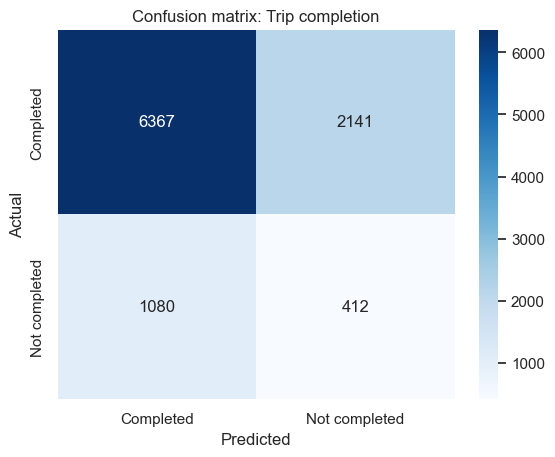

In [20]:
# ## Step 7: Predictive model 3: **Classification**
# Two targets:
# * **A. `demand_level`** (Low / Medium / High): multi-class
# * **B. `status`** (Completed vs Not completed): binary (cancellation risk)
# 
# Because classes are imbalanced / overlapping we compare against a majority-class baseline.

# ----------------------- CELL 20 (copy from here) -----------------------
def run_classifier(target_col, X, y, title, leaf=10):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
    num = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    cat = [c for c in X.columns if c not in num]
    pre_c = ColumnTransformer([("num", StandardScaler(), num),
                               ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    algos = {
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf,
                                                class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    }
    baseline = ytr.value_counts(normalize=True).max()
    rows, fit = [], {}
    for n, a in algos.items():
        p = Pipeline([("pre", pre_c), ("model", a)]).fit(Xtr, ytr)
        pr = p.predict(Xte)
        rows.append({"Model": n, "Accuracy": accuracy_score(yte, pr), "Macro F1": f1_score(yte, pr, average="macro")})
        fit[n] = (p, pr)
    res = pd.DataFrame(rows).round(3)
    print(f"=== {title} ===  (majority-class baseline accuracy = {baseline:.3f})")
    display(res)
    best = res.sort_values("Macro F1", ascending=False).iloc[0]["Model"]
    p, pr = fit[best]
    print("Best:", best); print(classification_report(yte, pr))
    sns.heatmap(confusion_matrix(yte, pr, labels=sorted(y.unique())), annot=True, fmt="d", cmap="Blues",
                xticklabels=sorted(y.unique()), yticklabels=sorted(y.unique()))
    plt.title(f"Confusion matrix: {title}"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()
    return p

# First, which features explain demand_level? Check how "pure" the label is inside each group.
def purity(keys):
    g = df.groupby(keys)["demand_level"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
    n = df.groupby(keys).size()
    return round((g * n).sum() / n.sum(), 3), len(n)
for keys in [["city"], ["hour"], ["city", "hour"], ["city", "payment_method"], ["city", "day_of_week", "hour"]]:
    p, k = purity(keys)
    print(f"{str(keys):40s} groups={k:5d}  purity={p}")
# purity = 1.0 for [city, day_of_week, hour] -> the label is a lookup on those three columns.

demand_feats = ["city", "day_of_week", "hour"]
demand_model = run_classifier("demand_level", df[demand_feats], df["demand_level"], "Demand level", leaf=1)

feat_cols = ["city", "payment_method", "distance_km", "fare_amount", "hour", "day_of_week", "is_weekend"]

# ----------------------- CELL 21 (copy from here) -----------------------
df["cancel_flag"] = np.where(df.status == "Completed", "Completed", "Not completed")
status_model = run_classifier("cancel_flag", df[feat_cols], df["cancel_flag"], "Trip completion")

In [22]:
joblib.dump(demand_model, "models/demand_model.joblib")
joblib.dump(status_model, "models/status_model.joblib")
print("Saved models")

Saved models


In [23]:
# ### Reading the results
# * **Fare regression**: fare is driven mostly by distance (r ~ 0.87). Linear regression is as good as the tree models (R2 ~ 0.76), so the relationship is essentially linear plus noise. City, payment method and time add almost nothing.
# * **Time series**: hourly volume is almost constant (about 2,080 trips per hour), so there is little pattern to forecast. Holt-Winters beats the seasonal-naive baseline modestly on MAE/MAPE; report the numbers and say plainly that the series is nearly flat.
# * **Demand classification**: `demand_level` is fully determined by **city + day of week + hour** (label purity = 1.0 for those groups), so a tree model recovers it almost perfectly. Mention in your report that this looks like a rule-based label in the dataset, not a pattern learned from trip counts (trips per hour are flat across demand levels).
# * **Completion (status) classification**: no feature predicts cancellations. The model does not beat the 85% majority-class baseline in accuracy and the minority-class F1 is low. This is a legitimate negative result, state it as such.

######################################################################
# ## Step 8: Save the cleaned data for the dashboard

# ----------------------- CELL 23 (copy from here) -----------------------
df_out = df.drop(columns=["date"]).copy()
df_out["time_of_day"] = df_out["time_of_day"].astype(str)
df_out.to_csv("data/uber_clean.csv", index=False)
print(df_out.shape, "-> data/uber_clean.csv")

######################################################################
# ## Step 9: Run the dashboard
# Save `app.py` next to this notebook, then in a terminal:
# ```
# streamlit run app.py
# ```


(50000, 25) -> data/uber_clean.csv
